# Curvature review: frozen previous code versus fixed code

This notebook embeds the **exact pre-fix source** from commit `99cf6c9e7186e422c132720de2b1294a247423ed` for intrinsic curvature, extrinsic curvature, their derivatives, patches and cyclic helpers. Each source file is copied verbatim below. It executes in isolated modules, including a redirected import hook, so the previous methods never call the fixed helpers by accident. No checkout of an old package is required.

Both implementations receive identical points, dtype, spacings, cyclic axes, patches and device. We report numerical differences, errors against analytic truth where available, failures, and median elapsed runtime. The seven fixes intentionally change behavior on bad inputs and ill-conditioned examples, so equality is not assumed to establish correctness. Image comparisons have no curvature ground truth.

`PROFILE="bounded"` executes **every mathematical case** in the current comparison notebook (including all seven slow ambient variants and optional total-grid families), all three dSprites shapes and all twenty COIL-20 objects, at smaller grids. It retains full intrinsic dimensions and all 4096 pixel features. It uses two resolutions per family and caps patches at 8. Small image nonperiodic axes have only one retained curvature coordinate; these runs establish coverage and behavior, not converged full-manifold results.

`PROFILE="original"` uses the source notebook's full ten-size mathematical schedules and original image parent grids/strides/patches. It is much more expensive, especially the 4D sphere, ambient-4096 ellipsoid and total grids. `INCLUDE_FULL_DSPRITES` controls its last dSprites run separately. No results of the bounded profile should be interpreted as measurements of the original profile.

Image preparation uses the original renderer conventions: balanced custom dSprites (blur .8) and augmented COIL-20, fixed [0,1] intensity scale, all classes, no PCA or per-resolution normalization. COIL-20 must already exist at `COIL20_PATH` or the loader's default location. CUDA timing is synchronized. Loading, generation and error/statistic calculations are excluded from curvature timings. Calls alternate old/new order across cases; the first call is excluded as warm-up and `REPEATS` timed calls are summarized by their median.


In [1]:
from pathlib import Path
from time import perf_counter
from statistics import median
import builtins
import csv
import hashlib
import json
import platform
import subprocess
import sys
import types

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from microscope.computations_grid import curvature as fixed_intrinsic
from microscope.computations_grid import curvature_extrinsic as fixed_extrinsic
from microscope.datasets import custom_dsprites, coil20
from microscope.manifold_examples.ellipsoid import ellipsoid_scalar_curvature
from microscope.manifold_examples.hyperboloid import hyperboloid_scalar_curvature
from microscope.manifold_examples.sphere import sphere_scalar_curvature
from microscope.manifold_examples.sampling_grid import sample_ellipsoid_on_grid, sample_hyperboloid_on_grid
from microscope.cyclic_dimensions import get_difference_intervals

PROFILE = "bounded"  # "bounded" or "original"
DEVICE = "cpu"  # Set explicitly to "cuda:0" for a GPU comparison.
DTYPE = np.float64
REPEATS = 2
CPU_THREADS = 2
INCLUDE_FULL_DSPRITES = False  # Applies to original-profile image grids.
N_SIZES = 10
SEED = 0
APPLY_RANDOM_ISOMETRY = False
INCLUDE_TOTAL_TEST_GRID = True
INCLUDE_SLOW_TESTS = True
SLOW_CASE_NAMES = None

assert PROFILE in ("bounded", "original")
assert REPEATS >= 1
if str(DEVICE).startswith("cuda") and not torch.cuda.is_available():
    raise RuntimeError("Requested CUDA is unavailable; select CPU explicitly.")
torch.set_num_threads(CPU_THREADS)
np.random.seed(SEED)
PACKAGE_ROOT = next(candidate for p in (Path.cwd(), *Path.cwd().parents)
                    for candidate in (p, p / "manifold-microscope")
                    if (candidate / "microscope/computations_grid/curvature.py").is_file())
OUTPUT_DIR = PACKAGE_ROOT.parent / "outputs/CURVATURE_FIXES_20261026" / PROFILE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREVIOUS_SOURCES = {}
PREVIOUS_HASHES = {}


### Frozen source: `microscope/cyclic_dimensions.py`

SHA-256: `23bc7025ce62077342b1851d059feb0cb88264619b909670b7b6fa56c47e731e`. The string below is the verbatim previous file, not a reimplementation.

In [2]:
PREVIOUS_SOURCES['microscope.cyclic_dimensions'] = r'''import numpy as np


def pad_cyclic_dimensions(
        array: np.ndarray,
        cyclic_dimensions: list[int],
        pad_sizes: list[int]
) -> np.ndarray:
    """Pad an array on both sides along cyclic dimensions in a circular way.

    Args:
        array: The array to pad.
        cyclic_dimensions: The dimensions along which to pad.
        pad_sizes: The size of the padding per cyclic dimension. It will be applied on both sides,
            i.e. the array will grow by 2*pad_size.

    Returns:
        The padded array.
    """
    if len(cyclic_dimensions) != len(pad_sizes):
        raise ValueError(
            f"Expected the number of cyclic dimensions ({len(cyclic_dimensions)}) to equal the number"
            f"of pad sizes ({len(pad_sizes)})."
        )
    for dim, pad_size in zip(cyclic_dimensions, pad_sizes):
        pad_front = array.take(indices=range(-pad_size, 0), axis=dim)
        pad_back = array.take(indices=range(pad_size), axis=dim)
        array = np.concatenate([pad_front, array, pad_back], axis=dim)

    return array


def get_difference_intervals(
        n_samples_per_dim: list[int],
        range_sizes: list[float],
        cyclic_dimensions: list[int]
) -> list[float]:
    """Computes the finite difference corresponding to the different dimensions. The difference is constant for all
    intervals and computed by dividing the range size with the number of samples if the dimension is cyclic else the
    number of samples minus 1.

    Args:
        n_samples_per_dim: The number of samples per dimension of the data.
        range_sizes: The value ranges along each dimension.
        cyclic_dimensions: Zero-based indices of the periodic grid axes.

    Returns:
        A list with the difference interval per dimension.
    """
    return [
        size / n_samples
        if dim in cyclic_dimensions
        else size / (n_samples - 1)

        for dim, [size, n_samples]
        in enumerate(zip(range_sizes, n_samples_per_dim))
    ]
'''
PREVIOUS_HASHES['microscope.cyclic_dimensions'] = '23bc7025ce62077342b1851d059feb0cb88264619b909670b7b6fa56c47e731e'

### Frozen source: `microscope/patches.py`

SHA-256: `392b5d8aff047bd3aeaec0bfcbbf1b289a00f90d6dc88a1d508a3f6555faaf31`. The string below is the verbatim previous file, not a reimplementation.

In [3]:
PREVIOUS_SOURCES['microscope.patches'] = r'''from typing import Optional

import numpy as np
from einops import einops

from microscope.cyclic_dimensions import pad_cyclic_dimensions


def extract_patches(
        array: np.ndarray,
        patch_sizes: list[int],
        overlaps: list[int],
        cyclic_dimensions: Optional[list[int]] = None,
        verbose: bool = False
) -> np.ndarray:
    """
    Generalized function to extract overlapping patches from the first n - d dimensions of a multidimensional array,
    leaving the last d dimensions untouched. If size of the array is not divisible by the resulting step size
    along all spatial dimensions, it will be wrap-padded to a compatible size. This means that the caller
    is responsible to truncate outputs on a later stage to compensate for those artificial padded values.

    Args:
        array: The input array to split.
        patch_sizes: The size of each patch along the first n - d dimensions.
        overlaps: The overlap along each of the first n - d dimensions.
        cyclic_dimensions: A set of dimensions where the grid is cyclic.
        verbose: If true it prints info and warning messages.


    Returns:
        A view of the overlapping patches, preserving their structure.
    """
    if cyclic_dimensions is None:
        cyclic_dimensions = []

    n_dim = len(patch_sizes)
    n_features = len(array.shape) - n_dim

    if len(overlaps) != n_dim:
        raise ValueError(
            f"The shape dimensions of the patch sizes ({n_dim}) differ from the "
            f"shape dimensions of the overlaps ({len(overlaps)})."
        )
    # Handle cyclic dimensions by padding the array
    array = pad_cyclic_dimensions(
        array,
        cyclic_dimensions=cyclic_dimensions,
        pad_sizes=[overlaps[dim] // 2 for dim in cyclic_dimensions]
    )

    patch_sizes = np.array(patch_sizes)
    overlaps = np.array(overlaps)
    step_sizes = patch_sizes - overlaps

    array_shape = np.array(array.shape[:n_dim])
    feature_shape = array.shape[n_dim:]

    residue = array_shape - overlaps - (step_sizes * ((array_shape - overlaps) // step_sizes))
    # noinspection PyUnresolvedReferences
    if (residue != 0).any():
        array_old_shape = array_shape
        # noinspection PyTypeChecker
        array = np.pad(
            array,
            pad_width=
            tuple((0, r) for r in (step_sizes - residue))
            + tuple(((0, 0) for _ in range(n_features))),
            mode="wrap"
        )
        array_shape = np.array(array.shape[:n_dim])
        feature_shape = array.shape[n_dim:]

        if verbose:
            print(
                f"WARNING: Array shape minus patch size {array_shape - patch_sizes} is not divisible by the step size "
                f"{step_sizes} (patch_size - overlap) along all dimensions. Zero padding the array of size "
                f"({array_old_shape}) to ({array_shape}) to compensate for that."
            )

    # Compute new shape and strides for patches
    patch_shape = tuple((array_shape - overlaps) // step_sizes) + tuple(patch_sizes) + feature_shape
    strides = array.strides
    patch_strides = (
        tuple(
            stride * step
            for stride, step
            in zip(strides[:n_dim], step_sizes))
        + strides[:n_dim]
        + strides[n_dim:]
    )
    # Extract overlapping patches using as_strided
    patches = np.lib.stride_tricks.as_strided(array, shape=patch_shape, strides=patch_strides)

    return patches


def stack_patches(patches: np.ndarray, n_features: int) -> np.ndarray:
    """
    Reconstructs an array from non-overlapping patches using einops.

    Args:
        patches: The patches arranged in a grid, with shape (g1, g2, ... p1, p2 ... n_features).
        n_features: The number of features which are not patched.

    Returns:
        An array with all the patches stacked along their corresponding dimensions.
    """
    # Number of spatial dimensions.
    n_dim = (len(patches.shape) - n_features) // 2

    # Dynamically construct einops pattern
    grid_dims = [f"grid{i}" for i in range(n_dim)]
    patch_dims = [f"patch{i}" for i in range(n_dim)]
    zipped_dims = [f"({g} {p})" for g, p in zip(grid_dims, patch_dims)]
    einops_pattern = f"{' '.join(grid_dims)} {' '.join(patch_dims)} ... -> {' '.join(zipped_dims)} ..."

    # Rearrange patches to reconstruct the array
    array = einops.rearrange(patches, einops_pattern)

    return array
'''
PREVIOUS_HASHES['microscope.patches'] = '392b5d8aff047bd3aeaec0bfcbbf1b289a00f90d6dc88a1d508a3f6555faaf31'

### Frozen source: `microscope/computations_grid/basic.py`

SHA-256: `b65b3f4eb6c5c9d99dac3c5810aac42bab855c3fe3ebf4b500ffbf55c1fcef0e`. The string below is the verbatim previous file, not a reimplementation.

In [4]:
PREVIOUS_SOURCES['microscope.computations_grid.basic'] = r'''import numpy as np
import torch

from microscope.patches import extract_patches


def partial_derivative_approximation(
    tensor: torch.Tensor,
    dim: int,
    difference_intervals: float
) -> torch.Tensor:
    """Estimate a central finite difference along one equally spaced grid axis.

    Args:
        tensor: Input tensor of shape (s0, ..., s_{n-1}).
        dim: Zero-based axis to differentiate.
        difference_intervals: Scalar coordinate spacing along that axis.

    Returns:
        A tensor of shape (s0, ..., s_dim - 2, ..., s_{n-1}) on the input
        device. Only axis dim is shortened; all other axes are preserved.
    """
    device = tensor.device
    length = tensor.shape[dim]

    t_plus = torch.index_select(tensor, dim=dim, index=torch.arange(2, length, device=device))
    t_minus = torch.index_select(tensor, dim=dim, index=torch.arange(0, length - 2, device=device))

    return (t_plus - t_minus) / (2 * difference_intervals)


def crop_dim_borders(tensor: torch.Tensor, dims: set[int], crop: int = 1) -> torch.Tensor:
    """Crop the borders of a given set of dimensions by a given value. This can be used to ensure that tensors which
    have been cropped along different dimension during estimations can be further cropped to have the same shape.

    Args:
        tensor: The tensor to be cropped.
        dims: A set of dimensions to crop the tensor on.
        crop: A integer indicating the amount of cropping at the start and end of a dimension of the tensor.

    Returns:
        The cropped tensor.
    """
    device = tensor.device

    for d in dims:
        length = tensor.shape[d]
        tensor = torch.index_select(tensor, dim=d, index=torch.arange(crop, length - crop, device=device))

    return tensor


def partial_derivatives_across_all_dims(
    tensor: torch.Tensor,
    manifold_dim: int,
    difference_intervals: list[float]
) -> torch.Tensor:
    """Differentiate along the first manifold_dim axes of an equally spaced grid.

    Args:
        tensor: Shape (s1, ..., sk, f1, ..., fl), with k = manifold_dim.
        manifold_dim: Number of parameter axes; remaining axes are features.
        difference_intervals: One coordinate spacing per parameter axis.

    Returns:
        A tensor of shape (s1 - 2, ..., sk - 2, f1, ..., fl, k) on the
        input device. All parameter axes are cropped; pad periodic axes first."""
    dim_idxs = set(range(manifold_dim))

    # This tensor had shape (s1 ... sk f1 ... fl k)
    partial_derivatives = torch.stack(
        [
            crop_dim_borders(
                partial_derivative_approximation(
                    tensor,
                    dim,
                    difference_intervals=range_size
                ),
                dim_idxs.difference({dim})
            )
            for dim, range_size in enumerate(difference_intervals)
        ],
        dim=-1
    )

    return partial_derivatives


def riemannian_metric(
        features_on_grid: torch.Tensor,
        difference_intervals: list[float]
) -> torch.Tensor:
    """Estimate the induced metric J.T @ J using central finite differences.

    Args:
        features_on_grid: Tensor of shape (s1, ..., sk, features).
        difference_intervals: One coordinate spacing per grid axis.

    Returns:
        A tensor of shape (s1 - 2, ..., sk - 2, k, k) on the input device.
        All grid axes are cropped; pad periodic axes first."""
    partial_derivatives = partial_derivatives_across_all_dims(
        features_on_grid,
        manifold_dim=len(features_on_grid.shape) - 1,
        difference_intervals=difference_intervals,
    )

    return partial_derivatives.transpose(-1, -2) @ partial_derivatives


def partial_derivatives_across_all_dims_batched(
    features_on_grid: np.ndarray,
    difference_intervals: list[float],
    patch_sizes: list[int],
    cyclic_dimensions: list[int],
    device: str | torch.device | None = None
):
    """Compute a NumPy grid's Jacobian in patches.

    Args:
        features_on_grid: Floating array of shape (s1, ..., sk, features).
        difference_intervals: One coordinate spacing per grid axis.
        patch_sizes: One patch size per grid axis, each greater than two.
        cyclic_dimensions: Zero-based periodic grid-axis indices.
        device: Torch device; None selects CUDA when available, otherwise CPU.

    Returns:
        A NumPy array of shape (s1_out, ..., sk_out, features, k), where
        s_i_out = s_i for periodic axes and s_i - 2 otherwise. The last axis
        indexes parameter derivatives. Results are detached from autograd.
    """
    if device is None:
        device = "cuda:0" if torch.cuda.is_available() else "cpu"

    dims = len(patch_sizes)
    overlaps = dims * [2]

    patches = extract_patches(
        features_on_grid,
        patch_sizes,
        overlaps,
        cyclic_dimensions=cyclic_dimensions
    )

    output_shape = tuple(s if i in cyclic_dimensions else s - 2
                         for i, s in enumerate(features_on_grid.shape[:dims]))
    derivative_array = np.empty((*output_shape, *features_on_grid.shape[dims:], dims),
                                dtype=features_on_grid.dtype)
    steps = np.asarray(patch_sizes) - 2
    for index in np.ndindex(*patches.shape[:dims]):
        patch = patches[index]
        points_pt_patch = torch.from_numpy(patch).to(device)

        volume_pred = partial_derivatives_across_all_dims(
            points_pt_patch,
            difference_intervals=difference_intervals,
            manifold_dim=dims
        ).cpu().detach().numpy()
        starts = np.asarray(index) * steps
        lengths = np.minimum(steps, np.asarray(output_shape) - starts)
        if np.all(lengths > 0):
            destination = tuple(slice(int(s), int(s + n)) for s, n in zip(starts, lengths))
            source = tuple(slice(0, int(n)) for n in lengths)
            derivative_array[destination] = volume_pred[source]

    return derivative_array

'''
PREVIOUS_HASHES['microscope.computations_grid.basic'] = 'b65b3f4eb6c5c9d99dac3c5810aac42bab855c3fe3ebf4b500ffbf55c1fcef0e'

### Frozen source: `microscope/computations_grid/curvature.py`

SHA-256: `b1c1045d8bc42dd2de96e93e0395e14c3dd871c7beeeaba8cdb8cfa77179f345`. The string below is the verbatim previous file, not a reimplementation.

In [5]:
PREVIOUS_SOURCES['microscope.computations_grid.curvature'] = r'''from typing import Callable, Optional

import numpy as np
import torch
from einops import einops

from microscope.computations_grid.basic import partial_derivatives_across_all_dims, crop_dim_borders, riemannian_metric
from microscope.patches import extract_patches


def christoffel_symbols(
    metric: torch.Tensor,
    metric_inv: torch.Tensor,
    difference_intervals: list[float]
):
    """Estimate Christoffel symbols of both kinds by finite differences.

    Args:
        metric: Metric tensor of shape (s1, ..., sk, k, k).
        metric_inv: Its precomputed inverse, with the same shape.
        difference_intervals: One coordinate spacing per grid axis.

    Returns:
        (gamma_first_kind, gamma_second_kind), each a tensor of shape
        (s1 - 2, ..., sk - 2, k, k, k). All grid axes are cropped."""
    n_dims = len(metric.shape) - 2
    metric_derivatives = partial_derivatives_across_all_dims(
        metric,
        manifold_dim=n_dims,
        difference_intervals=difference_intervals
    )
    gamma_first_kind = 0.5*(
        einops.rearrange(metric_derivatives, "... j k i-> ... i j k")
        + einops.rearrange(metric_derivatives, "... k i j-> ... i j k")
        - metric_derivatives
    )

    dim_idxs = set(np.arange(n_dims))
    metric_inv_cropped = crop_dim_borders(metric_inv, dim_idxs)
    gamma_second_kind = einops.einsum(metric_inv_cropped, gamma_first_kind, "... i r, ... j k r -> ... i j k")

    return gamma_first_kind, gamma_second_kind


def riemannian_curvature_tensor(
    gamma_first_kind: torch.Tensor,
    gamma_second_kind: torch.Tensor,
    difference_intervals: list[float],
    kinds: list[str] = ("first", "second")
) -> dict[str, Optional[torch.Tensor]]:
    """Estimate Riemann tensors by differentiating Christoffel symbols.

    Args:
        gamma_first_kind: First-kind symbols of shape (s1, ..., sk, k, k, k).
        gamma_second_kind: Second-kind symbols with the same shape.
        difference_intervals: One coordinate spacing per grid axis.
        kinds: Requested kinds: "first", "second", or both.

    Returns:
        A dictionary with keys "first" and "second"; unrequested entries are
        None. Requested tensors have shape (s1 - 2, ..., sk - 2, k, k, k, k).
        Each kind differentiates its corresponding Christoffel symbols."""
    n_dims = len(gamma_first_kind.shape) - 3
    gamma_derivatives_first_kind = partial_derivatives_across_all_dims(
        gamma_first_kind,
        manifold_dim=n_dims,
        difference_intervals=difference_intervals
    )
    gamma_derivatives_second_kind = partial_derivatives_across_all_dims(
        gamma_second_kind,
        manifold_dim=n_dims,
        difference_intervals=difference_intervals
    )

    dim_idxs = set(np.arange(n_dims))
    gamma_first_kind = crop_dim_borders(gamma_first_kind, dim_idxs)
    gamma_second_kind = crop_dim_borders(gamma_second_kind, dim_idxs)

    result = {"first": None, "second": None}

    if "first" in kinds:
        riemannian_tensor_first_kind = (
            einops.rearrange(gamma_derivatives_first_kind, "... j l i k -> ... i j k l")
            - einops.rearrange(gamma_derivatives_first_kind, "... j k i l -> ... i j k l")
            + einops.einsum(gamma_first_kind, gamma_second_kind, "... i l r, ... r j k -> ... i j k l")
            - einops.einsum(gamma_first_kind, gamma_second_kind, "... i k r, ... r j l -> ... i j k l")
        )
        result["first"] = riemannian_tensor_first_kind

    if "second" in kinds:
        riemannian_tensor_second_kind = (
            einops.rearrange(gamma_derivatives_second_kind, "... i j l k -> ... i j k l")
            - gamma_derivatives_second_kind
            + einops.einsum(gamma_second_kind, gamma_second_kind, "... r j l, ... i r k -> ... i j k l")
            - einops.einsum(gamma_second_kind, gamma_second_kind, "... r j k, ... i r l -> ... i j k l")
        )
        result["second"] = riemannian_tensor_second_kind

    return result


def scalar_curvature_batch(
    tensor: torch.Tensor,
    difference_intervals: list[float],
    normalize: bool = False
) -> torch.Tensor:
    """Estimate scalar curvature from a tensor grid using finite differences.

    Args:
        tensor: Tensor of shape (s1, ..., sd, features).
        difference_intervals: One coordinate spacing per grid axis.
        normalize: Divide scalar curvature by d * (d - 1); requires d >= 2.
            This does not rescale the manifold to unit volume.

    Returns:
        A tensor of shape (s1 - 6, ..., sd - 6) on the input device.
        All grid axes lose three samples at each end; pad periodic axes first.

    Raises:
        ValueError: If normalize is requested for d < 2."""
    intrinsic_dim = len(tensor.shape[:-1])
    if normalize and intrinsic_dim < 2:
        raise ValueError("Normalized scalar curvature requires intrinsic dimension at least 2.")

    metric = riemannian_metric(tensor, difference_intervals)
    metric_inv = torch.linalg.inv(metric)

    gamma_first_kind, gamma_second_kind = christoffel_symbols(
        metric,
        metric_inv,
        difference_intervals=difference_intervals
    )

    riemannian_tensor_first_kind = riemannian_curvature_tensor(
        gamma_first_kind,
        gamma_second_kind,
        difference_intervals=difference_intervals,
        kinds=["first"]
    )["first"]

    n_dims = set(np.arange(intrinsic_dim))
    metric_inv_cropped = crop_dim_borders(metric_inv, n_dims, crop=2)
    ricci_first_kind = einops.einsum(
        metric_inv_cropped,
        riemannian_tensor_first_kind, "... a b, ... a i b j -> ... i j"
    )
    if normalize:
        ricci_first_kind = 1 / (intrinsic_dim - 1) * ricci_first_kind

    scalar = einops.einsum(metric_inv_cropped, ricci_first_kind, "... i j, ... j i -> ...")
    if normalize:
        scalar = 1 / intrinsic_dim * scalar

    return scalar


def scalar_curvature(
    features_on_grid: np.ndarray,
    difference_intervals: list[float],
    cyclic_dimensions: list[int],
    patch_sizes: list[int],
    normalize: bool = False,
    device: str | torch.device | None = None
) -> np.ndarray:
    """Estimate scalar curvature of a NumPy grid in patches.

    Args:
        features_on_grid: Floating array of shape (s1, ..., sd, features).
        difference_intervals: One coordinate spacing per grid axis.
        cyclic_dimensions: Zero-based periodic grid-axis indices.
        patch_sizes: One patch size per grid axis, each greater than six.
        normalize: Divide scalar curvature by d * (d - 1); requires d >= 2.
            This does not rescale the manifold to unit volume.
        device: Torch device; None selects CUDA when available, otherwise CPU.

    Returns:
        A NumPy array of shape (s1_out, ..., sd_out), where s_i_out = s_i
        for periodic axes and s_i - 6 otherwise: one scalar curvature per point.
    """
    return _scalar_curvature_in_patches(
        features_on_grid, difference_intervals, cyclic_dimensions, patch_sizes,
        normalize, device, scalar_curvature_batch
    )


def _scalar_curvature_in_patches(
    features_on_grid: np.ndarray,
    difference_intervals: list[float],
    cyclic_dimensions: list[int],
    patch_sizes: list[int],
    normalize: bool,
    device: str | torch.device | None,
    batch_computation: Callable[[torch.Tensor, list[float], bool], torch.Tensor]
) -> np.ndarray:
    """Share the six-point halo and output stitching between curvature methods."""
    if device is None:
        device = "cuda:0" if torch.cuda.is_available() else "cpu"

    dims = len(patch_sizes)
    overlaps = dims * [6]

    patches = extract_patches(
        features_on_grid,
        patch_sizes,
        overlaps,
        cyclic_dimensions=cyclic_dimensions
    )

    output_shape = tuple(
        s if i in cyclic_dimensions else s - 6
        for i, s in enumerate(features_on_grid.shape[:-1])
    )
    curvature_array = np.empty(output_shape, dtype=features_on_grid.dtype)
    steps = np.asarray(patch_sizes) - 6
    # Flattening the strided patch grid copies every overlapping patch.
    for index in np.ndindex(*patches.shape[:dims]):
        patch = patches[index]
        points_pt_patch = torch.from_numpy(patch).to(device)

        curvature_pred = batch_computation(
            points_pt_patch,
            difference_intervals=difference_intervals,
            normalize=normalize
        ).cpu().detach().numpy()
        starts = np.asarray(index) * steps
        lengths = np.minimum(steps, np.asarray(output_shape) - starts)
        if np.all(lengths > 0):
            destination = tuple(slice(int(s), int(s + n)) for s, n in zip(starts, lengths))
            source = tuple(slice(0, int(n)) for n in lengths)
            curvature_array[destination] = curvature_pred[source]

    return curvature_array


def compute_total_curvature(element: np.ndarray, curvature: np.ndarray, range_sizes: list[float]) -> float:
    grid_volume = np.prod(range_sizes)

    # Note that the total curvature = curv * element * (grid_vol / N^2)
    # = (curv * element) / N^2 * grid_vol = mean(curv * element) * grid_vol.
    return (curvature * element).mean() * grid_volume
'''
PREVIOUS_HASHES['microscope.computations_grid.curvature'] = 'b1c1045d8bc42dd2de96e93e0395e14c3dd871c7beeeaba8cdb8cfa77179f345'

### Frozen source: `microscope/computations_grid/curvature_extrinsic.py`

SHA-256: `cb398721eaa63ac0940f0532bf601775116f58c77840c6e850bb615ac5db4be3`. The string below is the verbatim previous file, not a reimplementation.

In [6]:
PREVIOUS_SOURCES['microscope.computations_grid.curvature_extrinsic'] = r'''"""Finite-difference second fundamental form and Gauss scalar curvature."""

import numpy as np
import torch

from microscope.computations_grid.basic import (
    crop_dim_borders,
    partial_derivatives_across_all_dims,
)
from microscope.computations_grid.curvature import _scalar_curvature_in_patches


def _second_fundamental_form_and_metric(
    tensor: torch.Tensor,
    difference_intervals: list[float],
) -> tuple[torch.Tensor, torch.Tensor]:
    intrinsic_dim = tensor.ndim - 1
    grid_axes = set(range(intrinsic_dim))

    # J[..., a, i] is the ambient component a of the i-th tangent vector.
    tangent = partial_derivatives_across_all_dims(
        tensor, intrinsic_dim, difference_intervals
    )
    second_derivatives = partial_derivatives_across_all_dims(
        tangent, intrinsic_dim, difference_intervals
    )
    tangent = crop_dim_borders(tangent, grid_axes)

    metric = tangent.transpose(-1, -2) @ tangent
    tangent_components = torch.einsum(
        "...ar,...aij->...rij", tangent, second_derivatives
    )
    coefficients = torch.linalg.solve(
        metric, tangent_components.flatten(start_dim=-2)
    ).unflatten(-1, (intrinsic_dim, intrinsic_dim))
    form = second_derivatives - torch.einsum(
        "...ar,...rij->...aij", tangent, coefficients
    )
    return form, metric


def second_fundamental_form(
    tensor: torch.Tensor,
    difference_intervals: list[float],
) -> torch.Tensor:
    """Estimate the normal-valued second fundamental form of a grid embedding.

    Args:
        tensor: Embedded points of shape (s1, ..., sd, ambient_features).
        difference_intervals: One coordinate spacing per grid axis.

    Returns:
        A tensor of shape (s1 - 4, ..., sd - 4, ambient_features, d, d)
        on the input device. ``form[..., a, i, j]`` is the ambient component
        of B(∂i, ∂j). All grid axes are cropped by two at each end; pad
        periodic axes first. Full tangent rank is required.

    The tangent projection uses only a d-by-d solve. No ambient-sized normal
    basis or ambient-by-ambient projector is constructed.
    """
    form, _ = _second_fundamental_form_and_metric(tensor, difference_intervals)
    return form


def scalar_curvature_batch(
    tensor: torch.Tensor,
    difference_intervals: list[float],
    normalize: bool = False,
) -> torch.Tensor:
    """Estimate extrinsic scalar curvature via the Euclidean Gauss identity.

    The sign convention matches intrinsic ``curvature.scalar_curvature_batch``:
    a radius-r sphere has positive scalar curvature d(d-1)/r². ``normalize``
    divides by d(d-1), and requires d >= 2. The output has shape
    (s1 - 6, ..., sd - 6), matching the intrinsic batch function.

    For the separable sin/cos and sinh/cosh parameterizations used by the
    analytic manifold examples, matched central-difference factors cancel
    in the Gauss contraction. Their errors can therefore be dominated by
    roundoff even on coarse grids and grow as spacing decreases. Generic
    smooth embeddings retain finite-difference truncation error.
    """
    intrinsic_dim = tensor.ndim - 1
    if normalize and intrinsic_dim < 2:
        raise ValueError("Normalized scalar curvature requires intrinsic dimension at least 2.")

    form, metric = _second_fundamental_form_and_metric(tensor, difference_intervals)
    metric_inv = torch.linalg.inv(metric)

    # Sum over the ambient axis once. The remaining Gram tensor has only d^4
    # entries per point, even when the ambient embedding is very large.
    gram = torch.einsum("...aij,...akl->...ijkl", form, form)
    scalar = (
        torch.einsum("...ij,...kl,...ijkl->...", metric_inv, metric_inv, gram)
        - torch.einsum("...ik,...jl,...ijkl->...", metric_inv, metric_inv, gram)
    )
    if normalize:
        scalar = scalar / (intrinsic_dim * (intrinsic_dim - 1))

    # B needs two finite differences; the public curvature API keeps the
    # intrinsic method's three-point border and patch halo.
    return crop_dim_borders(scalar, set(range(intrinsic_dim)))


def scalar_curvature(
    features_on_grid: np.ndarray,
    difference_intervals: list[float],
    cyclic_dimensions: list[int],
    patch_sizes: list[int],
    normalize: bool = False,
    device: str | torch.device | None = None,
) -> np.ndarray:
    """Estimate extrinsic scalar curvature with the intrinsic NumPy grid API.

    For periodic axes, the output retains the input length; other axes lose
    three points at each end. ``device=None`` selects CUDA if available, else
    CPU. Patches bound the memory used by the ambient-vector-valued form.
    """
    return _scalar_curvature_in_patches(
        features_on_grid, difference_intervals, cyclic_dimensions, patch_sizes,
        normalize, device, scalar_curvature_batch
    )
'''
PREVIOUS_HASHES['microscope.computations_grid.curvature_extrinsic'] = 'cb398721eaa63ac0940f0532bf601775116f58c77840c6e850bb615ac5db4be3'

## Isolate and execute the previous implementation

In [7]:
previous_modules = {}
def previous_import(name, globals=None, locals=None, fromlist=(), level=0):
    if name in previous_modules:
        return previous_modules[name]
    return builtins.__import__(name, globals, locals, fromlist, level)

for name, source in PREVIOUS_SOURCES.items():
    assert hashlib.sha256(source.encode()).hexdigest() == PREVIOUS_HASHES[name]
    module = types.ModuleType("previous_" + name)
    module.__dict__["__builtins__"] = dict(vars(builtins), __import__=previous_import)
    previous_modules[name] = module
    exec(compile(source, "<frozen previous " + name + ">", "exec"), module.__dict__)
previous_intrinsic = previous_modules["microscope.computations_grid.curvature"]
previous_extrinsic = previous_modules["microscope.computations_grid.curvature_extrinsic"]
assert previous_intrinsic.extract_patches is previous_modules["microscope.patches"].extract_patches
assert previous_intrinsic.partial_derivatives_across_all_dims is previous_modules["microscope.computations_grid.basic"].partial_derivatives_across_all_dims
assert previous_extrinsic._scalar_curvature_in_patches is previous_intrinsic._scalar_curvature_in_patches
assert previous_intrinsic.scalar_curvature is not fixed_intrinsic.scalar_curvature

METHODS = {
    "intrinsic": {"previous": previous_intrinsic.scalar_curvature, "fixed": fixed_intrinsic.scalar_curvature},
    "extrinsic": {"previous": previous_extrinsic.scalar_curvature, "fixed": fixed_extrinsic.scalar_curvature},
}

def git_output(*args):
    return subprocess.check_output(["git", "-C", str(PACKAGE_ROOT), *args], text=True).strip()

source_paths = list(PREVIOUS_SOURCES)
source_paths += ["microscope._grid_validation", "microscope.computations_grid._curvature_geometry"]
current_hashes = {}
for name in source_paths:
    path = PACKAGE_ROOT / (name.replace(".", "/") + ".py")
    text = path.read_text()
    current_hashes[name] = hashlib.sha256(text.encode()).hexdigest()
    destination = OUTPUT_DIR / "current_sources" / path.relative_to(PACKAGE_ROOT)
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(text)
metadata = dict(profile=PROFILE, device=DEVICE, dtype=np.dtype(DTYPE).name,
                repeats=REPEATS, cpu_threads=CPU_THREADS, seed=SEED,
                python=sys.version, interpreter=sys.executable, platform=platform.platform(),
                torch=torch.__version__, numpy=np.__version__,
                previous_commit="99cf6c9e7186e422c132720de2b1294a247423ed",
                previous_hashes=PREVIOUS_HASHES, current_hashes=current_hashes,
                current_commit=git_output("rev-parse", "HEAD"), dirty=git_output("status", "--short"))
(OUTPUT_DIR / "environment.json").write_text(json.dumps(metadata, indent=2) + "\n")
(OUTPUT_DIR / "source.patch").write_text(git_output("diff", "--binary") + "\n")


Out[1]: 16518


## Dataset definitions from the current comparison notebook

These definitions and renderer parameters are copied from the pre-fix comparison notebook. Numerical kernels are selected separately above.

In [8]:
# 2D quadric cases; irregular-grid duplicates are omitted.
CASES_2D = {
    "sphere": dict(kind="ellipsoid", axes=[2, 2, 2], maximum=(1006, 1000), patches=[56, 56], fraction=.8),
    "ellipsoid": dict(kind="ellipsoid", axes=[1, 1.5, 3], maximum=(1006, 1000), patches=[56, 56], fraction=.8),
    "hyperboloid": dict(kind="hyperboloid", axes=[5, 1, 3], maximum=(1006, 1000), patches=[56, 56]),
}
if INCLUDE_TOTAL_TEST_GRID:
    for name, axes in (("sphere / total-test grid", [2, 2, 2]),
                       ("ellipsoid / total-test grid", [1, 1.5, 3])):
        CASES_2D[name] = dict(kind="ellipsoid", axes=axes, maximum=(10223, 10344),
                             patches=[1034, 1042], fraction=.9999)

GRAPH_CASES = {
    name: dict(kind="graph", graph=graph, maximum=(512, 512), patches=[56, 56])
    for name, graph in (("quartic", "quartic"), ("Gaussian", "gaussian"), ("rippled", "rippled"))
}


def grid_sizes(maximum, count=N_SIZES):
    sizes = np.rint(np.geomspace(16, np.asarray(maximum), count)).astype(int)
    sizes[-1] = maximum
    assert len({tuple(pair) for pair in sizes}) == count
    return [tuple(pair) for pair in sizes]


# Exact slow-test axes, maxima, ambient dimensions, and patch sizes.
SLOW_CASE_SPECS = {}
for ambient in (4, 100, 4096):
    SLOW_CASE_SPECS[f"3D ellipsoid / ambient {ambient}"] = dict(
        kind="ellipsoid", axes=[1, 1.5, 3, 1.8], ambient=ambient,
        maximum=(56, 56, 50) if ambient > 100 else (106, 106, 100),
        patches=[16]*3, fraction=.8)
for ambient in (4, 100):
    SLOW_CASE_SPECS[f"3D hyperboloid / ambient {ambient}"] = dict(
        kind="hyperboloid", axes=[5, 1, 3, 1], ambient=ambient,
        maximum=(156, 156, 150), patches=[56]*3)
for ambient in (5, 10):
    SLOW_CASE_SPECS[f"4D sphere / ambient {ambient}"] = dict(
        kind="sphere", axes=[2]*5, ambient=ambient,
        maximum=(106, 106, 106, 100), patches=[16]*4, fraction=.8)
selected = list(SLOW_CASE_SPECS) if SLOW_CASE_NAMES is None else SLOW_CASE_NAMES
SLOW_CASES = ({name: SLOW_CASE_SPECS[name] for name in selected}
              if INCLUDE_SLOW_TESTS else {})


def graph_height_and_curvature(u, v, graph):
    # For X=(u,v,f(u,v)), R=2*(f_uu*f_vv-f_uv**2)/(1+f_u**2+f_v**2)**2.
    # Differentiate each explicit height analytically, independently of the stencil.
    if graph == "quartic":
        height = .2*u**4 + .3*v**4 + .1*u*v
        fu, fv = .8*u**3 + .1*v, 1.2*v**3 + .1*u
        fuu, fvv, fuv = 2.4*u**2, 3.6*v**2, .1
    elif graph == "gaussian":
        height = .7*np.exp(-2*(u*u + v*v))
        fu, fv = -4*u*height, -4*v*height
        fuu, fvv, fuv = (16*u*u - 4)*height, (16*v*v - 4)*height, 16*u*v*height
    elif graph == "rippled":
        height = .2*np.sin(2*u) + .15*np.cos(3*v) + .1*u*v
        fu, fv = .4*np.cos(2*u) + .1*v, -.45*np.sin(3*v) + .1*u
        fuu, fvv, fuv = -.8*np.sin(2*u), -1.35*np.cos(3*v), .1
    else:
        raise ValueError(f"Unknown graph: {graph}")
    truth = 2*(fuu*fvv - fuv**2)/(1 + fu**2 + fv**2)**2
    return height, truth


def sample_case(spec, sizes):
    dim = len(sizes)
    if spec["kind"] == "graph":
        coordinates = [np.linspace(-1., 1., num=n) for n in sizes]
        u, v = np.meshgrid(*coordinates, indexing="ij")
        height, truth = graph_height_and_curvature(u, v, spec["graph"])
        points = np.stack([u, v, height], axis=-1)
        if APPLY_RANDOM_ISOMETRY:
            # Fixed rigid transform across resolutions for comparable roundoff.
            rng = np.random.default_rng(SEED)
            rotation, _ = np.linalg.qr(rng.normal(size=(3, 3)))
            points = points @ rotation + rng.uniform(-1., 1., size=3)
        return (points.astype(DTYPE, copy=False), truth[3:-3, 3:-3],
                [2/(n - 1) for n in sizes], [])
    cyclic_dimensions = [dim - 1]
    ambient = spec.get("ambient", dim + 1)
    if APPLY_RANDOM_ISOMETRY:
        # The sampler's translation uses NumPy's global RNG, in addition to seed.
        np.random.seed(SEED)
    sampling = dict(semi_axes=spec["axes"], n_samples_per_dim=list(sizes),
                    ambient_space_dim=ambient,
                    apply_random_isometry=APPLY_RANDOM_ISOMETRY, seed=SEED)
    if spec["kind"] in ("ellipsoid", "sphere"):
        points, axes, phis, _ = sample_ellipsoid_on_grid(
            **sampling, fraction_of_angles=spec["fraction"])
        range_sizes = [(2*spec["fraction"] - 1)*np.pi]*(dim - 1) + [2*np.pi]
        truth = (sphere_scalar_curvature(float(axes[0]), phis)
                 if spec["kind"] == "sphere" else ellipsoid_scalar_curvature(axes, phis))
    else:
        points, axes, phis, _ = sample_hyperboloid_on_grid(**sampling)
        range_sizes = [2.]*(dim - 1) + [2*np.pi]
        truth = hyperboloid_scalar_curvature(axes, phis)
    crop = (slice(3, -3),)*(dim - 1) + (slice(None),)
    intervals = get_difference_intervals(list(sizes), range_sizes, cyclic_dimensions)
    return points.astype(DTYPE, copy=False), truth[crop], intervals, cyclic_dimensions


In [9]:
from microscope.datasets import custom_dsprites, coil20
from microscope.computations_grid.volume import volume_element

IMAGE_WEIGHTING = "grid"  # "grid" or "volume" weighting for the mean.
INCLUDE_DSPRITES_FULL_GRID = True  # Set True to include the expensive all-strides-one run.
IMAGE_DENSITY_BINS = 60  # Normalized histogram estimate; common bins for both methods.
DSPRITES_CLASSES = None  # None = square, ellipse, heart; or e.g. ["heart"].
COIL20_CLASSES = None  # None = all 20 objects; or e.g. ["duck", "cat"].
# Axis order: (size, rotation, y, x), and (view, size, in-plane rotation).
DSPRITES_STRIDES = [(3, 2, 3, 3), (2, 2, 2, 2), (1, 2, 1, 1), (1, 1, 1, 1)]
COIL20_STRIDES = [(2, 3, 2), (2, 2, 2), (1, 2, 1), (1, 1, 1)]
IMAGE_PATCH_SIZES = {"dsprites": [10]*4, "coil20": [10]*3}


In [10]:
def image_class_grids(dataset, class_names=None):
    """Yield one component, fixed parent grid, spacings and periodic axes."""
    mapping = custom_dsprites.LABEL_MAPPING if dataset == "dsprites" else coil20.LABEL_MAPPING
    names = list(mapping.values()) if class_names is None else list(class_names)
    if not names or len(set(names)) != len(names) or not set(names) <= set(mapping.values()):
        raise ValueError(f"Select distinct classes from {list(mapping.values())}")
    if dataset == "dsprites":
        for name in names:
            # Exact balanced-renderer parameters, one class at a time to bound memory.
            images, _ = custom_dsprites.dsprites(
                image_size=64, sprite_initial_size=20, deformation_transforms_initial_size_factor=4,
                sprites=(name,), n_sizes=22, n_angles=16, min_size_ratio=.5, max_size_ratio=1.,
                max_translation=22, translation_stride=2, blur_sigma=.8,
                flat=False, scale=False, dtype=np.float32, processes=[None]*4, verbose=False)
            images = images[0]
            images += 1.
            images *= .5
            shape = images.shape[:-2]
            intervals = get_difference_intervals(list(shape), [1., 2*np.pi, 1., 1.], [1])
            yield name, images.reshape((*shape, 4096)), intervals, [1]
            del images
    elif dataset == "coil20":
        images, _ = coil20.extended_coil20(flat=False, scale=False,
                                          buffer_for_measure_estimation=3, verbose=False)
        images += 1.
        images *= .5
        shape = images.shape[1:-2]
        intervals = get_difference_intervals(list(shape), [2*np.pi, 1., 2*np.pi], [0, 2])
        for label, name in mapping.items():
            if name in names:
                yield name, images[label].reshape((*shape, 4096)), intervals, [0, 2]
    else:
        raise ValueError(f"Unknown image dataset: {dataset}")

def image_subgrid(grid, intervals, cyclic, strides):
    dim = grid.ndim - 1
    if len(strides) != dim or len(intervals) != dim:
        raise ValueError("One stride and spacing is required per varying grid coordinate.")
    for axis, stride in enumerate(strides):
        if not isinstance(stride, (int, np.integer)) or stride < 1:
            raise ValueError("Strides must be positive integers.")
        if axis in cyclic and grid.shape[axis] % stride:
            raise ValueError(f"Stride {stride} must divide periodic axis length {grid.shape[axis]}.")
        if len(range(0, grid.shape[axis], stride)) < 7:
            raise ValueError("Every sampled axis needs at least seven points for curvature.")
    selection = tuple(slice(None, None, int(s)) for s in strides) + (slice(None),)
    # No feature subsampling. Only this selected grid is promoted to computation dtype.
    points = np.ascontiguousarray(grid[selection], dtype=DTYPE)
    return points, [float(h*s) for h, s in zip(intervals, strides)]

In [11]:
def synchronize():
    if str(DEVICE).startswith("cuda"):
        torch.cuda.synchronize(DEVICE)

all_results = []
case_counter = 0

def save_report():
    (OUTPUT_DIR / "results.json").write_text(json.dumps(all_results, indent=2, allow_nan=True) + "\n")
    pd.DataFrame(all_results).to_csv(OUTPUT_DIR / "results.csv", index=False)


def compare_versions(family, name, points, intervals, cyclic, patches, truth=None):
    global case_counter
    kwargs = dict(difference_intervals=intervals, cyclic_dimensions=cyclic,
                  patch_sizes=patches, device=DEVICE)
    order = ("previous", "fixed") if case_counter % 2 == 0 else ("fixed", "previous")
    case_counter += 1
    for method, versions in METHODS.items():
        row = dict(family=family, case=name, shape=list(points.shape[:-1]),
                   features=points.shape[-1], points=int(np.prod(points.shape[:-1])),
                   dtype=str(points.dtype), device=DEVICE, patches=list(patches),
                   spacings=list(intervals), cyclic=list(cyclic), method=method)
        predictions = {}
        for version in order:
            fn = versions[version]
            try:
                # Untimed warm-up; same-size calls avoid planner/import startup.
                fn(points, **kwargs)
                times = []
                for _ in range(REPEATS):
                    synchronize()
                    start = perf_counter()
                    prediction = fn(points, **kwargs)
                    synchronize()
                    times.append(perf_counter() - start)
                predictions[version] = prediction
                row[version + "_seconds"] = median(times)
                row[version + "_times"] = times
                row[version + "_status"] = "ok" if np.isfinite(prediction).all() else "nonfinite"
                row[version + "_mean"] = float(prediction.mean())
                row[version + "_finite_fraction"] = float(np.isfinite(prediction).mean())
                if truth is not None:
                    assert prediction.shape == truth.shape
                    row[version + "_analytic_mae"] = float(np.abs(prediction - truth).mean())
            except (ValueError, TypeError, RuntimeError, np.linalg.LinAlgError) as error:
                row[version + "_status"] = "error"
                row[version + "_error"] = type(error).__name__ + ": " + str(error)
        if len(predictions) == 2:
            a, b = predictions["previous"], predictions["fixed"]
            assert a.shape == b.shape
            difference = b - a
            finite = np.isfinite(a) & np.isfinite(b)
            row["matching_shape"] = list(a.shape)
            row["bitwise_equal"] = bool(np.array_equal(a.view(np.uint8), b.view(np.uint8)))
            row["compared_fraction"] = float(finite.mean())
            if finite.any():
                row["max_abs_difference"] = float(np.max(np.abs(difference[finite])))
                row["mae_difference"] = float(np.mean(np.abs(difference[finite])))
                row["mean_signed_difference"] = float(np.mean(difference[finite]))
                row["relative_l2_difference"] = float(np.linalg.norm(difference[finite]) / max(np.linalg.norm(a[finite]), np.finfo(a.dtype).tiny))
            row["speedup_previous_over_fixed"] = row["previous_seconds"] / row["fixed_seconds"]
        if PROFILE == "bounded" and predictions:
            key = hashlib.sha256((family + name + str(points.shape) + method).encode()).hexdigest()[:16]
            np.savez_compressed(OUTPUT_DIR / (key + ".npz"), **predictions)
            row["pointwise_file"] = key + ".npz"
        all_results.append(row)
        save_report()
        print(f"{family} / {name}, {points.shape[:-1]}, {method}: "
              f"previous={row.get('previous_status')} fixed={row.get('fixed_status')} "
              f"max Δ={row.get('max_abs_difference', float('nan')):.3g}, "
              f"seconds {row.get('previous_seconds', float('nan')):.3g} → "
              f"{row.get('fixed_seconds', float('nan')):.3g}", flush=True)


def run_math_group(specs, family):
    for name, spec in specs.items():
        dims = len(spec["maximum"])
        sizes_to_run = grid_sizes(spec["maximum"]) if PROFILE == "original" else (
            [(16,)*dims, (32,)*dims] if dims == 2 else [(8,)*dims, (10,)*dims])
        for sizes in sizes_to_run:
            points, truth, intervals, cyclic = sample_case(spec, sizes)
            patches = spec["patches"] if PROFILE == "original" else [min(8, p) for p in spec["patches"]]
            compare_versions(family, name, points, intervals, cyclic, patches, truth)


def bounded_image_grids(dataset):
    if dataset == "dsprites":
        for name in custom_dsprites.LABEL_MAPPING.values():
            images, _ = custom_dsprites.dsprites(
                image_size=64, sprite_initial_size=20, deformation_transforms_initial_size_factor=4,
                sprites=(name,), n_sizes=7, n_angles=16, min_size_ratio=.5, max_size_ratio=1.,
                max_translation=7, translation_stride=2, blur_sigma=.8,
                flat=False, scale=False, dtype=np.float32, processes=[None]*4, verbose=False)
            images = images[0]
            images += 1.; images *= .5
            shape = images.shape[:-2]
            intervals = get_difference_intervals(list(shape), [1., 2*np.pi, 1., 1.], [1])
            yield name, images.reshape((*shape, 4096)), intervals, [1]
            del images
    else:
        images, _ = coil20.extended_coil20(n_sizes=1, n_angles=8, flat=False, scale=False,
                                          buffer_for_measure_estimation=3, verbose=False)
        images += 1.; images *= .5
        shape = images.shape[1:-2]
        intervals = get_difference_intervals(list(shape), [2*np.pi, 1., 2*np.pi], [0, 2])
        for label, name in coil20.LABEL_MAPPING.items():
            yield name, images[label].reshape((*shape, 4096)), intervals, [0, 2]


def run_image_group(dataset):
    components = image_class_grids(dataset) if PROFILE == "original" else bounded_image_grids(dataset)
    if PROFILE == "bounded":
        schedules = [(1,2,1,1), (1,1,1,1)] if dataset == "dsprites" else [(2,1,1), (1,1,1)]
    else:
        schedules = DSPRITES_STRIDES if dataset == "dsprites" else COIL20_STRIDES
        if dataset == "dsprites" and not INCLUDE_FULL_DSPRITES:
            schedules = [s for s in schedules if any(v != 1 for v in s)]
    for name, grid, intervals, cyclic in components:
        for strides in schedules:
            points, h = image_subgrid(grid, intervals, cyclic, strides)
            patches = IMAGE_PATCH_SIZES[dataset] if PROFILE == "original" else [8]*len(strides)
            compare_versions(dataset, name, points, h, cyclic, patches)
            del points
        del grid


## 2D mathematical manifolds

In [12]:
run_math_group(CASES_2D, '2D')

2D / sphere, (16, 16), intrinsic: previous=ok fixed=ok max Δ=5e-16, seconds 0.0167 → 0.0214
2D / sphere, (16, 16), extrinsic: previous=ok fixed=ok max Δ=6.11e-16, seconds 0.0117 → 0.0147
2D / sphere, (32, 32), intrinsic: previous=ok fixed=ok max Δ=6.11e-16, seconds 0.077 → 0.111
2D / sphere, (32, 32), extrinsic: previous=ok fixed=ok max Δ=6.11e-16, seconds 0.0537 → 0.079
2D / ellipsoid, (16, 16), intrinsic: previous=ok fixed=ok max Δ=2.66e-15, seconds 0.0147 → 0.0204
2D / ellipsoid, (16, 16), extrinsic: previous=ok fixed=ok max Δ=3.55e-15, seconds 0.0106 → 0.0146
2D / ellipsoid, (32, 32), intrinsic: previous=ok fixed=ok max Δ=4.44e-15, seconds 0.0753 → 0.106
2D / ellipsoid, (32, 32), extrinsic: previous=ok fixed=ok max Δ=4.44e-15, seconds 0.0543 → 0.0783
2D / hyperboloid, (16, 16), intrinsic: previous=ok fixed=ok max Δ=2.22e-16, seconds 0.0144 → 0.0206
2D / hyperboloid, (16, 16), extrinsic: previous=ok fixed=ok max Δ=6.11e-16, seconds 0.0106 → 0.0148
2D / hyperboloid, (32, 32), intrins

## 3D / 4D manifolds and all ambient dimensions

In [13]:
run_math_group(SLOW_CASE_SPECS, 'slow')

slow / 3D ellipsoid / ambient 4, (8, 8, 8), intrinsic: previous=ok fixed=ok max Δ=3.55e-15, seconds 0.00233 → 0.00378
slow / 3D ellipsoid / ambient 4, (8, 8, 8), extrinsic: previous=ok fixed=ok max Δ=4.88e-15, seconds 0.0018 → 0.00257
slow / 3D ellipsoid / ambient 4, (10, 10, 10), intrinsic: previous=ok fixed=ok max Δ=8.88e-15, seconds 0.0111 → 0.0182
slow / 3D ellipsoid / ambient 4, (10, 10, 10), extrinsic: previous=ok fixed=ok max Δ=8.88e-15, seconds 0.00853 → 0.0123
slow / 3D ellipsoid / ambient 100, (8, 8, 8), intrinsic: previous=ok fixed=ok max Δ=3.55e-15, seconds 0.003 → 0.00515
slow / 3D ellipsoid / ambient 100, (8, 8, 8), extrinsic: previous=ok fixed=ok max Δ=5.33e-15, seconds 0.00343 → 0.00526
slow / 3D ellipsoid / ambient 100, (10, 10, 10), intrinsic: previous=ok fixed=ok max Δ=8.88e-15, seconds 0.0144 → 0.0254
slow / 3D ellipsoid / ambient 100, (10, 10, 10), extrinsic: previous=ok fixed=ok max Δ=7.11e-15, seconds 0.0153 → 0.026
slow / 3D ellipsoid / ambient 4096, (8, 8, 8), 

## Quartic, Gaussian and rippled graphs

In [14]:
run_math_group(GRAPH_CASES, 'graphs')

graphs / quartic, (16, 16), intrinsic: previous=ok fixed=ok max Δ=6.66e-16, seconds 0.00889 → 0.0126
graphs / quartic, (16, 16), extrinsic: previous=ok fixed=ok max Δ=1.11e-15, seconds 0.00661 → 0.00913
graphs / quartic, (32, 32), intrinsic: previous=ok fixed=ok max Δ=1.78e-15, seconds 0.0586 → 0.0841
graphs / quartic, (32, 32), extrinsic: previous=ok fixed=ok max Δ=3.11e-15, seconds 0.044 → 0.0616
graphs / Gaussian, (16, 16), intrinsic: previous=ok fixed=ok max Δ=2.66e-15, seconds 0.00875 → 0.0122
graphs / Gaussian, (16, 16), extrinsic: previous=ok fixed=ok max Δ=5.33e-15, seconds 0.00639 → 0.0089
graphs / Gaussian, (32, 32), intrinsic: previous=ok fixed=ok max Δ=3.55e-15, seconds 0.0596 → 0.0853
graphs / Gaussian, (32, 32), extrinsic: previous=ok fixed=ok max Δ=1.24e-14, seconds 0.044 → 0.0608
graphs / rippled, (16, 16), intrinsic: previous=ok fixed=ok max Δ=8.88e-16, seconds 0.00893 → 0.0126
graphs / rippled, (16, 16), extrinsic: previous=ok fixed=ok max Δ=1.11e-15, seconds 0.00657 

## dSprites: all three classes, 4D / 4096 pixels

In [15]:
run_image_group('dsprites')

dsprites / square, (7, 8, 7, 7), intrinsic: previous=ok fixed=ok max Δ=6.38e-16, seconds 3.92 → 2.51
dsprites / square, (7, 8, 7, 7), extrinsic: previous=ok fixed=ok max Δ=8.24e-15, seconds 8.4 → 3.98
dsprites / square, (7, 16, 7, 7), intrinsic: previous=ok fixed=ok max Δ=4.51e-17, seconds 7.09 → 5.04
dsprites / square, (7, 16, 7, 7), extrinsic: previous=ok fixed=ok max Δ=5.76e-16, seconds 14.1 → 8.01
dsprites / ellipse, (7, 8, 7, 7), intrinsic: previous=ok fixed=ok max Δ=1.04e-16, seconds 4.01 → 2.53
dsprites / ellipse, (7, 8, 7, 7), extrinsic: previous=ok fixed=ok max Δ=9.02e-16, seconds 8.46 → 4.06
dsprites / ellipse, (7, 16, 7, 7), intrinsic: previous=ok fixed=ok max Δ=6.94e-17, seconds 7.22 → 5.11
dsprites / ellipse, (7, 16, 7, 7), extrinsic: previous=ok fixed=ok max Δ=1.17e-15, seconds 14.1 → 8.15
dsprites / heart, (7, 8, 7, 7), intrinsic: previous=ok fixed=ok max Δ=4.16e-17, seconds 4.06 → 2.58
dsprites / heart, (7, 8, 7, 7), extrinsic: previous=ok fixed=ok max Δ=5.48e-16, secon

## COIL-20: all twenty objects, 3D / 4096 pixels

In [16]:
run_image_group('coil20')

coil20 / duck, (9, 7, 8), intrinsic: previous=ok fixed=ok max Δ=1.11e-16, seconds 0.445 → 0.428
coil20 / duck, (9, 7, 8), extrinsic: previous=ok fixed=ok max Δ=3.78e-16, seconds 1.59 → 1.05
coil20 / duck, (18, 7, 8), intrinsic: previous=ok fixed=ok max Δ=4.34e-16, seconds 0.863 → 0.828
coil20 / duck, (18, 7, 8), extrinsic: previous=ok fixed=ok max Δ=8.88e-16, seconds 2.88 → 1.43
coil20 / wood_triangle, (9, 7, 8), intrinsic: previous=ok fixed=ok max Δ=1.18e-16, seconds 0.447 → 0.444
coil20 / wood_triangle, (9, 7, 8), extrinsic: previous=ok fixed=ok max Δ=3.09e-16, seconds 1.65 → 1.05
coil20 / wood_triangle, (18, 7, 8), intrinsic: previous=ok fixed=ok max Δ=1.01e-15, seconds 0.849 → 0.825
coil20 / wood_triangle, (18, 7, 8), extrinsic: previous=ok fixed=ok max Δ=8.47e-16, seconds 2.86 → 1.41
coil20 / car0, (9, 7, 8), intrinsic: previous=ok fixed=ok max Δ=1.04e-16, seconds 0.447 → 0.431
coil20 / car0, (9, 7, 8), extrinsic: previous=ok fixed=ok max Δ=3.61e-16, seconds 1.62 → 1.04
coil20 / c

## Review counterexamples

These small probes expose intended behavior changes. Failures on malformed inputs are expected. The cylindrical strip, anisotropic paraboloid and nearly collinear plane have independent scalar-curvature references.

In [17]:
angles = 2*np.pi*np.arange(8)/8
circle = np.column_stack([np.cos(angles), np.sin(angles)])
circle = np.concatenate([circle, circle[:2]])
z = np.arange(10)[:, None] + np.arange(11)[None, :]*.125
strip = np.concatenate([np.broadcast_to(circle[:, None], (10, 11, 2)), z[..., None]], axis=-1).copy()
compare_versions("review", "padding cylinder", strip, [1., .125], [], [9,9], np.zeros((4,5)))
h = .001
u,v = np.meshgrid(np.arange(-3,4)*h, np.arange(-3,4)*h, indexing="ij")
graph = np.stack([u,v,.5*(1e8*u*u + 1e-8*v*v)],axis=-1)
compare_versions("review", "Gauss cancellation", graph, [h,h], [], [7,7], np.full((1,1),2.))
u,v = np.meshgrid(np.arange(9.),np.arange(9.),indexing="ij")
plane = np.stack([u+v,1e-8*v,np.zeros_like(u)],axis=-1)
compare_versions("review", "full rank narrow plane", plane, [1.,1.], [], [9,9], np.zeros((3,3)))
graph = np.stack([u,v,u*u+v*v],axis=-1)
compare_versions("review", "missing spacing", graph, [1.], [], [9,9])
compare_versions("review", "integer input", graph.astype(np.int64), [1.,1.], [], [9,9])
compare_versions("review", "reversed grid", graph[::-1], [1.,1.], [], [9,9])


review / padding cylinder, (10, 11), intrinsic: previous=error fixed=ok max Δ=nan, seconds nan → 0.00217
review / padding cylinder, (10, 11), extrinsic: previous=error fixed=ok max Δ=nan, seconds nan → 0.00161
review / Gauss cancellation, (7, 7), intrinsic: previous=ok fixed=ok max Δ=0, seconds 0.000403 → 0.000581
review / Gauss cancellation, (7, 7), extrinsic: previous=ok fixed=ok max Δ=2, seconds 0.000307 → 0.000434
review / full rank narrow plane, (9, 9), intrinsic: previous=error fixed=ok max Δ=nan, seconds nan → 0.000593
review / full rank narrow plane, (9, 9), extrinsic: previous=error fixed=ok max Δ=nan, seconds nan → 0.000447
review / missing spacing, (9, 9), intrinsic: previous=ok fixed=error max Δ=nan, seconds 0.000308 → nan
review / missing spacing, (9, 9), extrinsic: previous=error fixed=error max Δ=nan, seconds nan → nan
review / integer input, (9, 9), intrinsic: previous=ok fixed=error max Δ=nan, seconds 0.000436 → nan
review / integer input, (9, 9), extrinsic: previous=o

## Numerical and runtime report

Differences are fixed minus previous. Runtime ratios greater than one favor the fixed implementation. A previous failure followed by fixed success is recorded as a recovery, not a numerical equality. Cases with both methods failing require inspection: rank-deficient rendered grids have no well-defined curvature for this stencil. Aggregate timing is descriptive and includes different grid sizes; individual rows are the primary comparison.

In [18]:
report = pd.DataFrame(all_results)
columns = ["family", "case", "shape", "method", "previous_status", "fixed_status",
           "max_abs_difference", "mae_difference", "previous_analytic_mae", "fixed_analytic_mae",
           "previous_seconds", "fixed_seconds", "speedup_previous_over_fixed"]
display(report.reindex(columns=columns))
summary = report.groupby(["family", "method"]).agg(
    cases=("case", "count"),
    previous_ok=("previous_status", lambda s: int((s == "ok").sum())),
    fixed_ok=("fixed_status", lambda s: int((s == "ok").sum())),
    maximum_difference=("max_abs_difference", "max"),
    previous_seconds=("previous_seconds", "sum"),
    fixed_seconds=("fixed_seconds", "sum"))
display(summary)
summary.to_csv(OUTPUT_DIR / "summary.csv")
failures = report[(report.previous_status != "ok") | (report.fixed_status != "ok")]
display(failures.reindex(columns=["family", "case", "shape", "method", "previous_error", "fixed_error"]))


,family,case,shape,method,previous_status,fixed_status,max_abs_difference,mae_difference,previous_analytic_mae,fixed_analytic_mae,previous_seconds,fixed_seconds,speedup_previous_over_fixed
0,2D,sphere,"[16, 16]",intrinsic,ok,ok,4.996004e-16,1.297573e-16,7.854210e-03,7.854210e-03,0.016696,0.021402,0.780120
1,2D,sphere,"[16, 16]",extrinsic,ok,ok,6.106227e-16,1.467576e-16,8.236467e-16,7.990136e-16,0.011732,0.014729,0.796520
2,2D,sphere,"[32, 32]",intrinsic,ok,ok,6.106227e-16,1.383776e-16,1.846348e-03,1.846348e-03,0.076958,0.111036,0.693087
3,2D,sphere,"[32, 32]",extrinsic,ok,ok,6.106227e-16,1.406460e-16,3.094880e-15,3.115430e-15,0.053707,0.078965,0.680142
4,2D,ellipsoid,"[16, 16]",intrinsic,ok,ok,2.664535e-15,3.240463e-16,9.161206e-02,9.161206e-02,0.014691,0.020376,0.721008
...,...,...,...,...,...,...,...,...,...,...,...,...,...
159,review,missing spacing,"[9, 9]",extrinsic,error,error,NaN,NaN,NaN,NaN,NaN,NaN,NaN
160,review,integer input,"[9, 9]",intrinsic,ok,error,NaN,NaN,NaN,NaN,0.000436,NaN,NaN
161,review,integer input,"[9, 9]",extrinsic,ok,error,NaN,NaN,NaN,NaN,0.000329,NaN,NaN
162,review,reversed grid,"[9, 9]",intrinsic,error,ok,NaN,NaN,NaN,NaN,NaN,0.000597,NaN


cases  previous_ok  ...  previous_seconds  fixed_seconds
family   method                         ...                                 
2D       extrinsic     10           10  ...          0.326389       0.461187
         intrinsic     10           10  ...          0.452096       0.638911
coil20   extrinsic     40           40  ...         88.498115      48.142845
         intrinsic     40           40  ...         25.256484      24.918840
dsprites extrinsic      6            6  ...         67.946252      36.547786
         intrinsic      6            6  ...         33.682848      22.957438
graphs   extrinsic      6            6  ...          0.152729       0.210995
         intrinsic      6            6  ...          0.206658       0.291782
review   extrinsic      6            2  ...          0.000637       0.002943
         intrinsic      6            3  ...          0.001147       0.003939
slow     extrinsic     14           14  ...          1.667962       2.062868
         intrinsic     14           14  ...          1.020410       1.488924

[12 rows x 6 columns]

,family,case,shape,method,previous_error,fixed_error
152,review,padding cylinder,"[10, 11]",intrinsic,_LinAlgError: linalg.inv: (Batch element 35): ...,NaN
153,review,padding cylinder,"[10, 11]",extrinsic,_LinAlgError: torch.linalg.solve: (Batch eleme...,NaN
156,review,full rank narrow plane,"[9, 9]",intrinsic,_LinAlgError: linalg.inv: (Batch element 0): T...,NaN
157,review,full rank narrow plane,"[9, 9]",extrinsic,_LinAlgError: torch.linalg.solve: (Batch eleme...,NaN
158,review,missing spacing,"[9, 9]",intrinsic,NaN,"ValueError: Expected 2 difference intervals, o..."
159,review,missing spacing,"[9, 9]",extrinsic,"RuntimeError: unflatten: Provided sizes [2, 2]...","ValueError: Expected 2 difference intervals, o..."
160,review,integer input,"[9, 9]",intrinsic,NaN,TypeError: Curvature requires float32 or float...
161,review,integer input,"[9, 9]",extrinsic,NaN,TypeError: Curvature requires float32 or float...
162,review,reversed grid,"[9, 9]",intrinsic,ValueError: At least one stride in the given n...,NaN
163,review,reversed grid,"[9, 9]",extrinsic,ValueError: At least one stride in the given n...,NaN


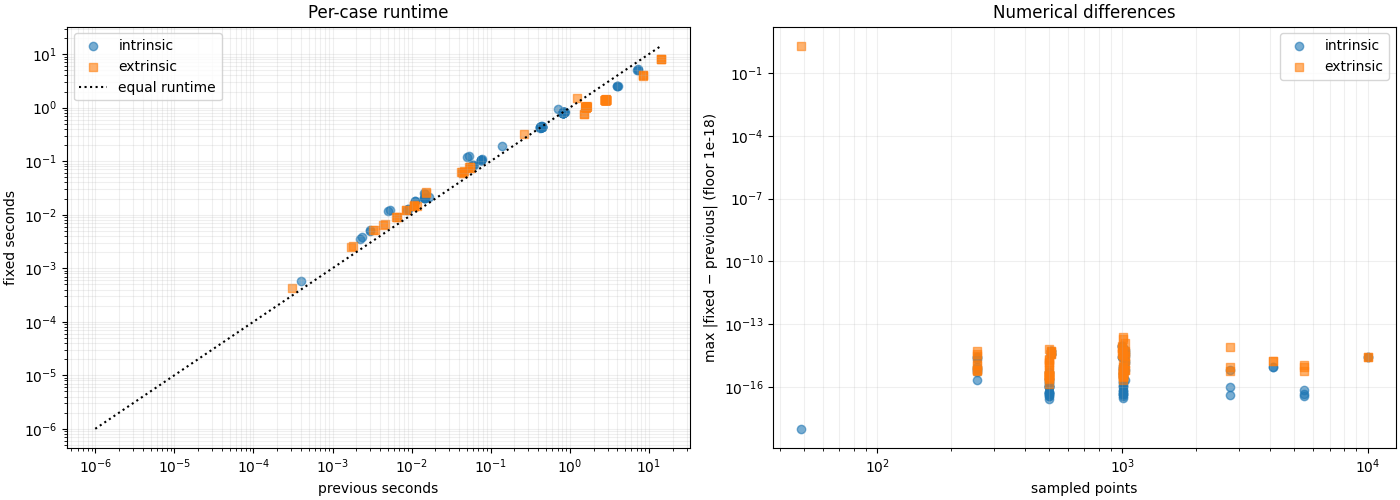

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for method, marker in (("intrinsic", "o"), ("extrinsic", "s")):
    rows = report[(report.method == method) & (report.previous_status == "ok") & (report.fixed_status == "ok")]
    axes[0].scatter(rows.previous_seconds, rows.fixed_seconds, marker=marker, alpha=.6, label=method)
    axes[1].scatter(rows.points, rows.max_abs_difference.clip(lower=1e-18), marker=marker, alpha=.6, label=method)
limit = max(report.previous_seconds.max(), report.fixed_seconds.max())
axes[0].plot([1e-6, limit], [1e-6, limit], "k:", label="equal runtime")
axes[0].set(xscale="log", yscale="log", xlabel="previous seconds", ylabel="fixed seconds", title="Per-case runtime")
axes[1].set(xscale="log", yscale="log", xlabel="sampled points", ylabel="max |fixed − previous| (floor 1e-18)", title="Numerical differences")
for ax in axes:
    ax.grid(True, which="both", alpha=.2); ax.legend()
plt.show()


The fixed implementation validates dtype, spacings, periodic axes and patch extents; crops unused padding before inversions; uses QR tangent factors with rank diagnostics; and sums sectional Gauss terms instead of cancelling large diagonal self-contributions. True rank loss remains an error, without regularization. QR cannot remove all sensitivity of metric differentiation in ill-conditioned charts. The separate metric-first speedup is not implemented here.

The saved tables and source snapshots under `OUTPUT_DIR` identify the exact executed profile and code state. CPU/GPU, dtype, pixel rendering precision, grid sizes and timing repetitions are recorded. An executed bounded notebook does not establish full-grid agreement or GPU behavior.


## Recorded bounded CPU execution — 2026-10-26

Executed all 15 mathematical cases/ambient variants and all 23 image classes at two bounded resolutions, for both curvature methods. The additional six review probes document intentional fixes and validation errors. No original-profile maximum-grid or GPU execution is claimed.

| Family | Method | Comparisons | Maximum absolute difference | Previous seconds | Fixed seconds | Previous / fixed |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| coil20 | extrinsic | 40 | 2.38e-14 | 88.498 | 48.143 | 1.84× |
| coil20 | intrinsic | 40 | 1.01e-15 | 25.256 | 24.919 | 1.01× |
| dsprites | extrinsic | 6 | 8.24e-15 | 67.946 | 36.548 | 1.86× |
| dsprites | intrinsic | 6 | 6.38e-16 | 33.683 | 22.957 | 1.47× |
| mathematical | extrinsic | 30 | 1.24e-14 | 2.147 | 2.735 | 0.79× |
| mathematical | intrinsic | 30 | 8.88e-15 | 1.679 | 2.420 | 0.69× |

Times are sums of per-case medians (two timed repetitions after warm-up); they exclude image preparation and comparisons. Values above 1× favor the fixed implementation. QR/rank validation adds overhead on small mathematical cases; partial-patch corrections reduce work in these bounded image cases. These timings do not predict performance on the full original grids.

The ordinary cases all completed under both versions. Their maximum pointwise change was 2.38e-14. The review probes separately recover the artificial-padding, narrow-plane and reversed-stride failures, reject malformed spacing/integer input, and correct the extrinsic anisotropic-graph curvature from 0 to 2.

The dSprites bounded renderer used seven sizes, sixteen rotations and seven translations per direction (translation coordinates −7,−5,…,5). COIL used eighteen original views, seven sizes and eight in-plane rotations. Each image keeps all 4096 pixels. Nonperiodic cropping leaves few retained coordinates in these small runs, so agreement here is not convergence evidence.

Machine-readable per-case values/times/errors are in `results.csv` and `results.json` under the recorded `OUTPUT_DIR`; pointwise arrays are in the referenced NPZ files. The environment, input PNG hashes and exact numerical source snapshots are retained there.